Before starting import the necessary libs 

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt
%matplotlib inline

### STEP :- 1 Import csv file, Understand about data & Objective 

1. Why are I doing this case study?
   - Banks and lending companines give loans to customers. But some customers pay back thier loans, While others fail to repay. This is called Loan Default.
   - My aim is to explore the lending dataset and understand the data, identify data-quality issues, and find patterns that may be related to loan defaults. EDA helps me understand the data before building a prediticive model.

2. What is the Problem statement?
    - To perform Exploratory Data Analysis (EDA) on lending default risk data to understand customer and loan characteristics, identity data quailty, Issues on data and patterns associated with loan defaults.

3. What am I trying to find?
    - I want to check whether the dataset contains missing value, Duplicate records, unusual data, and relationships between variable. I also want to explore whether customer and loan characteristics differ between default and non-default groups.

    #Personal Understanding - I shouldn't assume that the dataset is clean or that useful patterns exist before analysing it, I need to check the data step by step and draw conclusion based on the result. Even if I don't find a clear pattern, it doesn't mean there is no lending risk.

### Objective: The obejective of this study is to perform Exploratory Data Analysis (EDA) on lending default risk data to understand the dataset.

In [4]:
df=pd.read_csv('Lending_Default_Risk_Data.csv')

### STEP 2 :- Understand about dataset

In [5]:
df.head()
### The first 5 rows

,Loan_ID,Age,Annual_Income,Employment_Length,Home_Ownership,Loan_Intent,Loan_Amount,Interest_Rate,Debt_To_Income,Credit_Score,Previous_Defaults,Education_Level,Employment_Status,Marital_Status,Credit_Grade,Has_CoSigner,Region,Income_Verification,Default_Status
0,LN004476,55.0,63886.0,2.0,RENT,PERSONAL,9830,17.658023,27.229361,586.0,0,Bachelors,Employed,Married,E,No,North,Source Verified,1
1,LN001890,-6.0,35948.0,8.0,MORTGAGE,MEDICAL,14284,18.047484,27.526683,625.0,1,Doctorate,Employed,Single,D,No,East,Not Verified,1
2,LN010373,61.0,36977.0,10.0,RENT,VENTURE,2159,7.474256,50.550452,NaN,0,Bachelors,Employed,Single,A,No,North,Verified,0
3,LN012219,35.0,70546.0,17.0,RENT,HOMEIMPROVEMENT,31441,14.980514,39.906569,678.0,1,High School,Employed,Single,C,No,East,Source Verified,1
4,LN003996,28.0,47128.0,10.0,MORTGAGE,HOMEIMPROVEMENT,24110,7.276745,53.900137,586.0,0,Bachelors,Employed,Married,E,Yes,Central,Verified,1


In [6]:
df.tail()
### The last 5 rows

,Loan_ID,Age,Annual_Income,Employment_Length,Home_Ownership,Loan_Intent,Loan_Amount,Interest_Rate,Debt_To_Income,Credit_Score,Previous_Defaults,Education_Level,Employment_Status,Marital_Status,Credit_Grade,Has_CoSigner,Region,Income_Verification,Default_Status
15345,LN005192,49.0,128021.0,23.0,MORTGAGE,MEDICAL,22415,17.864809,0.691971,595.0,1,Bachelors,Self-Employed,Single,E,No,West,Verified,1
15346,LN013419,36.0,33271.0,NaN,MORTGAGE,NaN,25338,18.995565,22.148418,653.0,1,MASTERS,Self-Employed,Married,C,No,West,Verified,1
15347,LN005391,39.0,182190.0,NaN,MORTGAGE,MEDICAL,2732,11.547376,13.761839,755.0,0,High School,Employed,Married,A,No,East,Source Verified,0
15348,LN000861,51.0,41525.0,6.0,OWN,HOMEIMPROVEMENT,27580,8.404466,25.710670,692.0,0,Bachelors,Employed,Married,C,No,South,Verified,1
15349,LN007271,41.0,57335.0,16.0,MORTGAGE,HOMEIMPROVEMENT,14799,17.131060,34.438838,557.0,0,Associates,Employed,Married,E,No,West,Not Verified,1


In [7]:
df.shape
### No. of rows - 15350
### No. of Columns - 19

(15350, 19)

In [8]:
df.size
### Total number of elements

291650

In [9]:
df.info()
##### Total Information about dataset

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15350 entries, 0 to 15349
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Loan_ID              15350 non-null  object 
 1   Age                  15095 non-null  float64
 2   Annual_Income        14545 non-null  float64
 3   Employment_Length    13817 non-null  float64
 4   Home_Ownership       15149 non-null  object 
 5   Loan_Intent          15168 non-null  object 
 6   Loan_Amount          15350 non-null  int64  
 7   Interest_Rate        14489 non-null  float64
 8   Debt_To_Income       15042 non-null  float64
 9   Credit_Score         15059 non-null  float64
 10  Previous_Defaults    15350 non-null  int64  
 11  Education_Level      15023 non-null  object 
 12  Employment_Status    15105 non-null  object 
 13  Marital_Status       15350 non-null  object 
 14  Credit_Grade         15350 non-null  object 
 15  Has_CoSigner         15196 non-null 

In [10]:
df.columns
### Gives the complete columns availabe in dataset

Index(['Loan_ID', 'Age', 'Annual_Income', 'Employment_Length',
       'Home_Ownership', 'Loan_Intent', 'Loan_Amount', 'Interest_Rate',
       'Debt_To_Income', 'Credit_Score', 'Previous_Defaults',
       'Education_Level', 'Employment_Status', 'Marital_Status',
       'Credit_Grade', 'Has_CoSigner', 'Region', 'Income_Verification',
       'Default_Status'],
      dtype='object')

In [11]:
df.describe()
### Describe about only numerical data in Statistical terms 

,Age,Annual_Income,Employment_Length,Loan_Amount,Interest_Rate,Debt_To_Income,Credit_Score,Previous_Defaults,Default_Status
count,15095.000000,1.454500e+04,13817.000000,15350.000000,14489.000000,15042.000000,15059.000000,15350.000000,15350.000000
mean,43.472011,8.949866e+04,14.418832,20496.449577,13.560478,31.046291,669.844810,0.297850,0.773941
std,15.212348,4.170142e+05,10.371505,11233.540284,5.565177,29.481581,77.421869,0.548289,0.418291
min,-10.000000,-2.410700e+04,0.000000,1001.000000,0.000000,0.013734,53.000000,0.000000,0.000000
25%,31.000000,4.001000e+04,6.000000,10721.000000,9.230662,15.065623,618.000000,0.000000,1.000000
50%,43.000000,6.027600e+04,13.000000,20563.000000,13.533078,30.239210,669.000000,0.000000,1.000000
75%,56.000000,9.057100e+04,22.000000,30179.000000,17.702164,44.978965,721.000000,1.000000,1.000000
max,143.000000,1.467969e+07,39.000000,39997.000000,123.280000,995.570000,1188.000000,5.000000,1.000000


### Problem identified 
- Age contains suspicious values
Minimum age is -10, and Maximum is 143.

- Annual income has extreme values
Mean annual income is approximately ₹89,497, while the Median is ₹60,276.

- Interest rate has an unusual maximum
Maximum interest rate is approximately 123.28.

- Debt-to-income has an unusual maximum
Maximum Debt_To_Income value is approximately 995.57.

- Credit score has unusual values
Minimum credit score is 53, and Maximum is 1,188

### STEP 3 - Initial Data Quality Checks

In [12]:
df.describe(include="all")
# descriptive statistics of both Numercial and Categorical data

,Loan_ID,Age,Annual_Income,Employment_Length,Home_Ownership,Loan_Intent,Loan_Amount,Interest_Rate,Debt_To_Income,Credit_Score,Previous_Defaults,Education_Level,Employment_Status,Marital_Status,Credit_Grade,Has_CoSigner,Region,Income_Verification,Default_Status
count,15350,15095.000000,1.454500e+04,13817.000000,15149,15168,15350.000000,14489.000000,15042.000000,15059.000000,15350.000000,15023,15105,15350,15350,15196,15350,15134,15350.000000
unique,15000,NaN,NaN,NaN,12,6,NaN,NaN,NaN,NaN,NaN,15,4,4,6,2,5,3,NaN
top,LN012373,NaN,NaN,NaN,MORTGAGE,MEDICAL,NaN,NaN,NaN,NaN,NaN,Bachelors,Employed,Married,C,No,South,Verified,NaN
freq,2,NaN,NaN,NaN,6688,2616,NaN,NaN,NaN,NaN,NaN,5888,12010,6871,4044,12111,3854,6090,NaN
mean,NaN,43.472011,8.949866e+04,14.418832,NaN,NaN,20496.449577,13.560478,31.046291,669.844810,0.297850,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.773941
std,NaN,15.212348,4.170142e+05,10.371505,NaN,NaN,11233.540284,5.565177,29.481581,77.421869,0.548289,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.418291
min,NaN,-10.000000,-2.410700e+04,0.000000,NaN,NaN,1001.000000,0.000000,0.013734,53.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
25%,NaN,31.000000,4.001000e+04,6.000000,NaN,NaN,10721.000000,9.230662,15.065623,618.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000
50%,NaN,43.000000,6.027600e+04,13.000000,NaN,NaN,20563.000000,13.533078,30.239210,669.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000
75%,NaN,56.000000,9.057100e+04,22.000000,NaN,NaN,30179.000000,17.702164,44.978965,721.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000


In [13]:
df.dtypes
# Data type of every column

Loan_ID                 object
Age                    float64
Annual_Income          float64
Employment_Length      float64
Home_Ownership          object
Loan_Intent             object
Loan_Amount              int64
Interest_Rate          float64
Debt_To_Income         float64
Credit_Score           float64
Previous_Defaults        int64
Education_Level         object
Employment_Status       object
Marital_Status          object
Credit_Grade            object
Has_CoSigner            object
Region                  object
Income_Verification     object
Default_Status           int64
dtype: object

In [14]:
df.nunique()
### Helps to exact non-repeated values &
### Counts unique values in each column, excluding missing values by default.

Loan_ID                15000
Age                       77
Annual_Income          13347
Employment_Length         40
Home_Ownership            12
Loan_Intent                6
Loan_Amount            12416
Interest_Rate          14152
Debt_To_Income         14700
Credit_Score             450
Previous_Defaults          6
Education_Level           15
Employment_Status          4
Marital_Status             4
Credit_Grade               6
Has_CoSigner               2
Region                     5
Income_Verification        3
Default_Status             2
dtype: int64

In [15]:
df.isnull().sum()
# Missing values in every column

Loan_ID                   0
Age                     255
Annual_Income           805
Employment_Length      1533
Home_Ownership          201
Loan_Intent             182
Loan_Amount               0
Interest_Rate           861
Debt_To_Income          308
Credit_Score            291
Previous_Defaults         0
Education_Level         327
Employment_Status       245
Marital_Status            0
Credit_Grade              0
Has_CoSigner            154
Region                    0
Income_Verification     216
Default_Status            0
dtype: int64

In [16]:
df.duplicated().sum()
# Count of exact duplicate 

np.int64(350)

In [17]:
duplicate_loan_ids = df["Loan_ID"].duplicated().sum()
#Check is Loan_ID is unique
print("Number of repeated Loan_ID records:", duplicate_loan_ids)

repeated_ids = df[
    df['Loan_ID'].duplicated(keep=False)
    ].sort_values('Loan_ID')

repeated_ids

Number of repeated Loan_ID records: 350


,Loan_ID,Age,Annual_Income,Employment_Length,Home_Ownership,Loan_Intent,Loan_Amount,Interest_Rate,Debt_To_Income,Credit_Score,Previous_Defaults,Education_Level,Employment_Status,Marital_Status,Credit_Grade,Has_CoSigner,Region,Income_Verification,Default_Status
12142,LN000031,66.0,54012.0,35.0,OWN,PERSONAL,15076,21.316732,39.185691,753.0,0,Bachelors,Employed,Married,A,Yes,East,Not Verified,1
6615,LN000031,66.0,54012.0,35.0,OWN,PERSONAL,15076,21.316732,39.185691,753.0,0,Bachelors,Employed,Married,A,Yes,East,Not Verified,1
270,LN000190,45.0,36803.0,15.0,OTHER,DEBTCONSOLIDATION,3963,12.164580,32.531074,647.0,0,High School,Employed,Single,D,No,West,Verified,0
15307,LN000190,45.0,36803.0,15.0,OTHER,DEBTCONSOLIDATION,3963,12.164580,32.531074,647.0,0,High School,Employed,Single,D,No,West,Verified,0
13117,LN000275,57.0,79621.0,37.0,MORTGAGE,HOMEIMPROVEMENT,16764,19.837442,8.587132,670.0,0,Bachelors,Employed,Single,C,No,West,Source Verified,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8867,LN014925,65.0,70755.0,36.0,RENT,HOMEIMPROVEMENT,29208,15.485432,4.645338,620.0,0,Bachelors,Employed,Widowed,D,No,Central,Source Verified,1
9766,LN014932,37.0,43672.0,19.0,MORTGAGE,MEDICAL,36505,7.220000,7.207808,670.0,2,Bachelors,Employed,Single,C,No,South,Verified,1
6900,LN014932,37.0,43672.0,19.0,MORTGAGE,MEDICAL,36505,7.220000,7.207808,670.0,2,Bachelors,Employed,Single,C,No,South,Verified,1
2905,LN014945,45.0,55215.0,16.0,MORTGAGE,DEBTCONSOLIDATION,5839,13.694725,13.634186,633.0,1,High School,Employed,Married,D,No,Central,Not Verified,1


In [18]:
df["Default_Status"].value_counts()

# Counts each value in the default-status column.
### Selects the specific column named "Default_Status"
### .value_counts():Counts exactly how many times each unique category -
###  - appears in that column.
### 11880 + 3470 = 15350

Default_Status
1    11880
0     3470
Name: count, dtype: int64

In [19]:
df["Default_Status"].value_counts(normalize=True)*100

Default_Status
1    77.394137
0    22.605863
Name: proportion, dtype: float64

Obversation - Duplicate Records

- The dataset contains **350 exact duplicate rows**.
- There are **350 repeated Loan_ID values**, representing 350 repeated IDs.
- Inspection confirms that the repeated Loan_ID records are exact duplicates in this dataset.
- These records should be reviewed before removal to avoid counting the same loan more than once.

### STEP 4 : Investigate suspicious values

In [20]:
invalid_age_records = df.loc[
    (df['Age'] < 0) | (df['Age'] > 100),
     ['Loan_ID', 'Age']
    ]
#Identify age outside the chosen vaild range of 0 to 100

print('Number of records with invalid age:', len(invalid_age_records))

invalid_age_records

Number of records with invalid age: 30


,Loan_ID,Age
1,LN001890,-6.0
8,LN012808,137.0
333,LN000543,117.0
368,LN000170,-10.0
727,LN002251,143.0
1009,LN008992,-1.0
1019,LN000863,131.0
1138,LN003899,123.0
1214,LN007041,-7.0
1590,LN002313,-10.0


In [21]:
df.loc[(df["Age"] < 0) |(df["Age"] > 100), ["Loan_ID", "Age"]]
#loc means location, Filter of positive (-0 and +100) shows in a table

,Loan_ID,Age
1,LN001890,-6.0
8,LN012808,137.0
333,LN000543,117.0
368,LN000170,-10.0
727,LN002251,143.0
1009,LN008992,-1.0
1019,LN000863,131.0
1138,LN003899,123.0
1214,LN007041,-7.0
1590,LN002313,-10.0


Some ages are invalid, such as -6, -7 and etc.,, Moreover some ages are above 100 too such as 117, 143 and etc.,, 

In [22]:
df.loc[df["Annual_Income"] < 0, ['Loan_ID', 'Annual_Income']]
#The table summaries the negative income in dataset

,Loan_ID,Annual_Income
45,LN003403,-4642.0
1136,LN007636,-4722.0
2515,LN003704,-14388.0
4130,LN002953,-24107.0
5163,LN010065,-20691.0
5331,LN007636,-4722.0
5400,LN012774,-21002.0
5765,LN010766,-22197.0
9033,LN005607,-16672.0
10242,LN000003,-20201.0


In [23]:
df.loc[df["Annual_Income"] > 100, ['Loan_ID', 'Annual_Income']]
#The table summaries the negative income in dataset

,Loan_ID,Annual_Income
0,LN004476,63886.0
1,LN001890,35948.0
2,LN010373,36977.0
3,LN012219,70546.0
4,LN003996,47128.0
...,...,...
15345,LN005192,128021.0
15346,LN013419,33271.0
15347,LN005391,182190.0
15348,LN000861,41525.0


In [26]:
Q1 = df['Annual_Income'].quantile(0.25)
Q3 = df['Annual_Income'].quantile(0.75)
IQR = Q3 - Q1
#Calculate the Interquartile Range 

lower_limit = Q1 - 1.5 *IQR
upper_limit = Q3 + 1.5 *IQR
#Calculate the outlier thresholds

income_outliers = df.loc[
    (df['Annual_Income'] < lower_limit) |
    (df['Annual_Income'] > upper_limit),
    ['Loan_ID', 'Annual_Income']]
#identify potential outliers 

print('Lower outlier threshold:', lower_limit)
print('Upper outlier threshold:', upper_limit)
print('Number of potential income outliers:', len(income_outliers))

income_outliers

Lower outlier threshold: -35831.5
Upper outlier threshold: 166412.5
Number of potential income outliers: 702


,Loan_ID,Annual_Income
23,LN011296,2.228030e+05
44,LN005152,1.226465e+06
101,LN010612,3.919519e+05
122,LN013791,1.980240e+05
148,LN008671,2.358910e+05
...,...,...
15141,LN005916,7.163960e+06
15180,LN013774,1.714860e+05
15181,LN008111,1.713120e+05
15301,LN007735,4.190300e+05


This flag potential outliers based on the income distribution. An outlier is not automatically an error 

In [27]:
suspicious_checks = { 
    "Interest_Rate_above_100": df['Interest_Rate'] > 100,
    "Debt_To_Income_above_100": df['Debt_To_Income'] > 100,
    "Credit_Score_below_300": df['Credit_Score'] < 300,
    "Credit_Score_below_850": df['Credit_Score'] > 850,
}

for check_name, condition in suspicious_checks.items():
    print(f"{check_name}: {condition.sum()} records")
# Inspect supicious value in important numerical columns 

Interest_Rate_above_100: 6 records
Debt_To_Income_above_100: 30 records
Credit_Score_below_300: 15 records
Credit_Score_below_850: 20 records


If the column represents a percentage, value above 100% mean debt exceeds income. That may be possible, but the scale and calculation must be confirmed 

Debt-to-Income (DTI) ratio is the percentage of your gross monthly income that goes toward paying your monthly debt obligations. Lenders use it to measure your ability to manage monthly payments and assess credit risk when you apply for a loan or mortgage.

This identifies scores outside a common credit-score range. The dataset may use a different scoring system, so confirm its definition first. we can see the credit score 53 in min and 1,188 in max

### STEP 5: Findings from Initial Data Quality Investigation

#### A. Suspicious Values

* **Age:** 30 records have ages below 0 or above 100. Negative ages are invalid, while ages above 100 need to be checked.
* **Annual Income:** 15 records have negative income values. The IQR method flagged 702 records with unusually high income values, but these may also be genuine high-income cases.
* **Interest Rate:** 6 records have interest rates above 100. I need to check the units and meaning of this column before deciding whether these values are incorrect.
* **Debt-to-Income:** 30 records have values above 100. I need to understand how this ratio is defined before deciding whether these values are unusual or invalid.
* **Credit Score:** 35 records have values outside the common range of 300–850. I need to confirm which credit scoring system is used before treating these values as errors.

#### B. What Needs to Be Checked Before Cleaning?

1. Check the dataset documentation to understand each column and its expected range.
2. Investigate whether negative income values and extreme financial values are genuine or caused by data-entry errors.
3. Check whether duplicate records should be removed based on what each row represents in the dataset.
4. Decide how to handle confirmed errors and unusual values without removing valid data unnecessarily.

#### Conclusion

The initial data-quality investigation identified duplicate records and several suspicious values in different columns. However, I need to investigate these values further before deciding how to clean the dataset. I should not remove or change any records just because they were flagged during the checks.


### STEP 6: Duplicate Removal

In [28]:
df_clean = df.drop_duplicates()
# Create a new dataset without exact duplicate rows

print("Original dataset:", df.shape)
print("After removing duplicates:", df_clean.shape)
# Compare the original and cleaned dataset

print("Remanining duplicates:", df_clean.duplicated().sum())
#Verify that no exact duplicate rows remain

Original dataset: (15350, 19)
After removing duplicates: (15000, 19)
Remanining duplicates: 0


In [29]:
original_rows = len(df)
# Record the original number of rows

df_clean = df.drop_duplicates().copy()
# Remove exact duplicate rows

rows_removed = original_rows - len(df_clean)
# Calculate rows removed

remaining_duplicates = df_clean.duplicated().sum()
# Verify the cleaned dataset
print("Original rows:", original_rows)
print("Rows removed:", rows_removed)
print("Rows after cleaning:", len(df_clean))
print("Remaining duplicates:", remaining_duplicates)

assert remaining_duplicates == 0, \
    "Duplicate rows remain after cleaning."

assert len(df_clean) + rows_removed == original_rows, \
    "Row-count verification failed."

Original rows: 15350
Rows removed: 350
Rows after cleaning: 15000
Remaining duplicates: 0


Duplicates Values
> The total dataset is 15350 rows and 19 columns.
> Found total number of 350 duplicate rows and removed from the working copy
> The cleaned copy, df_cleam - now containts 15000 rows and 19 columns , moreover no duplicates remain. 

### STEP 7 - Missing Value Analysis 

In [30]:
missing_percentage = df_clean.isnull().mean()* 100
missing_percentage.sort_values(ascending=True)
# Calculate missing - value percentages by column

Loan_ID                0.000000
Region                 0.000000
Credit_Grade           0.000000
Marital_Status         0.000000
Previous_Defaults      0.000000
Loan_Amount            0.000000
Default_Status         0.000000
Has_CoSigner           1.000000
Loan_Intent            1.200000
Home_Ownership         1.333333
Income_Verification    1.400000
Employment_Status      1.600000
Age                    1.666667
Credit_Score           1.866667
Debt_To_Income         2.000000
Education_Level        2.133333
Annual_Income          5.260000
Interest_Rate          5.593333
Employment_Length      9.993333
dtype: float64

Missing Values
>  Employment_Length  9.99333% Is the highest of missing value, Interest_Rate  5.593333% of missing value, Annual_Income - 5.260000% of missing value, and , The other missing value is also shown above 

In [32]:
missing_by_status=( 
    df_clean
        .groupby("Default_Status")
        .agg(lambda column: column.isnull().sum())
)
missing_by_status
#Count missing values by default status

,Loan_ID,Age,Annual_Income,Employment_Length,Home_Ownership,Loan_Intent,Loan_Amount,Interest_Rate,Debt_To_Income,Credit_Score,Previous_Defaults,Education_Level,Employment_Status,Marital_Status,Credit_Grade,Has_CoSigner,Region,Income_Verification
Default_Status,,,,,,,,,,,,,,,,,,
0,0,45,179,345,43,44,0,185,75,72,0,62,62,0,0,36,0,53
1,0,205,610,1154,157,136,0,654,225,208,0,258,178,0,0,114,0,157


In [33]:
missing_pct_by_status = (
    df_clean
        .groupby('Default_Status')
        .agg(lambda column: column.isna().mean() * 100)
)

missing_pct_by_status.round(2)
# Calculate missing-value percentage within each status group
#.round(2) directly - Cleaned up the workflow by rounding the percentages to 2 decimal places before saving it to the variable.

,Loan_ID,Age,Annual_Income,Employment_Length,Home_Ownership,Loan_Intent,Loan_Amount,Interest_Rate,Debt_To_Income,Credit_Score,Previous_Defaults,Education_Level,Employment_Status,Marital_Status,Credit_Grade,Has_CoSigner,Region,Income_Verification
Default_Status,,,,,,,,,,,,,,,,,,
0,0.0,1.32,5.27,10.15,1.27,1.29,0.0,5.44,2.21,2.12,0.0,1.82,1.82,0.0,0.0,1.06,0.0,1.56
1,0.0,1.77,5.26,9.95,1.35,1.17,0.0,5.64,1.94,1.79,0.0,2.22,1.53,0.0,0.0,0.98,0.0,1.35


Obervestion :
>missing_by_status shows 'counts' & missing_pct_by_status shows 'in percentage'
>
>
>Missing values are in both missing_by_status & missing_pct_by_status, the raw missing values counts are high in status 1 in many columns, So, I need to compare the missing values percentage to understand in the default groups. No decision had been made about handling missing values at this stage. 

In [34]:
missing_summary = pd.DataFrame({
    "Missing_Count": df_clean.isnull().sum(),
    "Missing_Percentage": df_clean.isnull().mean() * 100
})

missing_summary = missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)
missing_summary.round(2)
#Count missing values in the cleaned dataset

,Missing_Count,Missing_Percentage
Employment_Length,1499,9.99
Interest_Rate,839,5.59
Annual_Income,789,5.26
Education_Level,320,2.13
Debt_To_Income,300,2.00
Credit_Score,280,1.87
Age,250,1.67
Employment_Status,240,1.60
Income_Verification,210,1.40
Home_Ownership,200,1.33


This table summaries the number and percentage of missing value in each column, helping identify variables that require further investigation. 

In [35]:
missing_cols= df_clean.columns[df_clean.isnull().any()]
#Identify columns with missing values

numeric_missing = df_clean[missing_cols].select_dtypes(
    include='number'
).columns.tolist()

categorical_missing = df_clean[missing_cols].select_dtypes(
    exclude='number'
).columns.tolist()
#Separete numerical and categorrical columns 

print('numerical columns:', numeric_missing)
print('categorical columns:', categorical_missing)

numerical columns: ['Age', 'Annual_Income', 'Employment_Length', 'Interest_Rate', 'Debt_To_Income', 'Credit_Score']
categorical columns: ['Home_Ownership', 'Loan_Intent', 'Education_Level', 'Employment_Status', 'Has_CoSigner', 'Income_Verification']


Observation: 
> The missing value analysis identified 12 columns with missing value, including 6 numerical and 6 categorical columns.

### STEP 8 - Suspicious Value Treatment decision

Variable---------	 initial decision
- Age ->	           Investigate negative ages and unusually high ages
- Annual_Income ->     Investigate negative values; retain high values until verified
- Interest_Rate ->      Verify extreme values and units
- Debt_To_Income ->	    Verify the ratio's scale and definition
- Credit_Score ->	    Verify the scoring range
- Exact duplicates->	Already removed in df_clean; original df preserved

In [36]:
df_clean["Employment_Length"].describe()
#Checking describe of Employment_Length

count    13501.000000
mean        14.415080
std         10.366984
min          0.000000
25%          6.000000
50%         13.000000
75%         22.000000
max         39.000000
Name: Employment_Length, dtype: float64

In [37]:
df_clean["Employment_Length"].value_counts(dropna=False).sort_index()
#check the most frequent employment_Length values

Employment_Length
0.0      563
1.0      607
2.0      562
3.0      587
4.0      524
5.0      531
6.0      500
7.0      496
8.0      476
9.0      457
10.0     446
11.0     450
12.0     435
13.0     398
14.0     402
15.0     403
16.0     414
17.0     376
18.0     337
19.0     350
20.0     330
21.0     311
22.0     325
23.0     308
24.0     245
25.0     293
26.0     267
27.0     255
28.0     236
29.0     207
30.0     188
31.0     179
32.0     169
33.0     145
34.0     146
35.0     151
36.0     131
37.0     107
38.0     107
39.0      87
NaN     1499
Name: count, dtype: int64

In [38]:
(df_clean["Employment_Length"].dropna() % 1 != 0).sum()
# Check whether employment length contains decimal values

np.int64(0)

In [39]:
df_clean.loc[
    df_clean["Employment_Length"] > df_clean["Age"],
    ["Loan_ID","Age","Employment_Length"]]
#CHECK Employment len against customer age 

,Loan_ID,Age,Employment_Length
1,LN001890,-6.0,8.0
368,LN000170,-10.0,6.0
1009,LN008992,-1.0,1.0
1214,LN007041,-7.0,11.0
1670,LN001796,-6.0,14.0
1928,LN006979,-10.0,1.0
2841,LN003976,-5.0,10.0
4317,LN005305,-9.0,14.0
4628,LN007400,-4.0,4.0
5198,LN011810,-5.0,28.0


In [40]:
df_clean.loc[
    df_clean['Age'] > 100,
    ['Loan_ID', 'Age']]
#Display age's above 100

,Loan_ID,Age
8,LN012808,137.0
333,LN000543,117.0
727,LN002251,143.0
1019,LN000863,131.0
1138,LN003899,123.0
1832,LN013168,122.0
2409,LN003782,135.0
2585,LN005971,125.0
2695,LN004352,130.0
3099,LN003018,111.0


Here we can see the age greater than 100, Such as from '111 to 143'

In [41]:
df_clean.loc[
    df_clean['Age'] < 0,
    ['Loan_ID', 'Age']] 
#Display age's below 0

,Loan_ID,Age
1,LN001890,-6.0
368,LN000170,-10.0
1009,LN008992,-1.0
1214,LN007041,-7.0
1590,LN002313,-10.0
1670,LN001796,-6.0
1928,LN006979,-10.0
2841,LN003976,-5.0
4317,LN005305,-9.0
4628,LN007400,-4.0


Here we can see the age lesser than 0, Such as from '-1.0 to -10.0'

In [42]:
df_clean['Age'].isnull().sum()
#Count missing values in Age 

np.int64(250)

Observation:
> Shows there are 250 missing values

In [43]:
original_rows = len(df)
#Record the original dataset size 

df_clean = df.drop_duplicates().copy()
#Remove exact duplicate row

rows_removed = original_rows - len(df_clean)
#Calculate the number of rows removed by minus 

remaining_duplicates = df_clean.duplicated().sum()
#Confirm or verify the results 

print('Original dataset shape:', df.shape)
print('Cleaned dataset shape:', df_clean.shape)
print('Duplicate rows removed:', rows_removed)
print('Remaining Exact duplicates', remaining_duplicates)
#prints the value 

assert remaining_duplicates ==0
assert len(df_clean) + rows_removed == original_rows
# Verify that zero duplicates remain and that the row math matches perfectly

Original dataset shape: (15350, 19)
Cleaned dataset shape: (15000, 19)
Duplicate rows removed: 350
Remaining Exact duplicates 0


In [44]:
df_clean['Age'].describe()

count    14750.000000
mean        43.468610
std         15.220117
min        -10.000000
25%         31.000000
50%         43.000000
75%         56.000000
max        143.000000
Name: Age, dtype: float64

Observation:
> We got the missing values as 250, here got count as 14750 which gives total of 15000.
> The age falls min on -10 and max on 143.
> The mean age is 43.47.

The symolb(|) means (or). It counts rows where age is negative OR greater than 100

In [45]:
negative_age = (df_clean['Age'] < 0).sum()
# Count negative age or lesser than 0

high_age = (df_clean['Age'] > 100).sum()
#Count age above 100 or greater than 100

print('Negative age:', negative_age)
print('Age above 100:', high_age)

Negative age: 15
Age above 100: 15


Observation:
> The Age column contains 250 missing value.
> The negative age is = 15 & Age above 100 is = 15

In [46]:
outside_range = (
    (df_clean['Age'] < 0 ) |
    (df_clean['Age'] > 100)).sum()    
print('Records outside the range :', outside_range)
#Count age outside the range 0 - 100 

Records outside the range : 30


In [47]:
df_work = df_clean.copy()
# Create a separate working copy
invalid_age = (
    df_work['Age'].notna()
    & (
        (df_work['Age'] < 0)
        | (df_work['Age'] > 100)
    )
)
# Identify invalid ages, excluding existing missing values

invalid_age_count = invalid_age.sum()
# Count invalid ages before cleaning

df_work.loc[invalid_age, 'Age'] = np.nan
# Replace invalid ages with missing values

remaining_invalid_age = (
    (df_work['Age'] < 0)
    | (df_work['Age'] > 100)
).sum()
# Verify the changes
print("Invalid ages corrected:", invalid_age_count)
print("Invalid ages remaining:", remaining_invalid_age)
print("Total missing ages:", df_work['Age'].isna().sum())

Invalid ages corrected: 30
Invalid ages remaining: 0
Total missing ages: 280


#### Annual income 

In [48]:
df_work['Annual_Income'].describe()
#describe about annual income

count    1.421100e+04
mean     8.988128e+04
std      4.218204e+05
min     -2.410700e+04
25%      3.996000e+04
50%      6.023700e+04
75%      9.048450e+04
max      1.467969e+07
Name: Annual_Income, dtype: float64

In [49]:
(df_work['Annual_Income'] < 0).sum()
#Count negative or lesser than zero in income values

np.int64(14)

Observation:
> Means 14 values are under zero in Annual income

In [50]:
df_work.loc[
    df_work['Annual_Income'] < 0, 
    ['Loan_ID', 'Annual_Income']]
#Table summeries the value below zero 

,Loan_ID,Annual_Income
45,LN003403,-4642.0
1136,LN007636,-4722.0
2515,LN003704,-14388.0
4130,LN002953,-24107.0
5163,LN010065,-20691.0
5400,LN012774,-21002.0
5765,LN010766,-22197.0
9033,LN005607,-16672.0
10242,LN000003,-20201.0
10254,LN003407,-8421.0


Observation:
> There 14 data in this table which shows the negative and lesser than zero values.
> The negative value from -4642 to -241070.

In [51]:
negative_income_count = (
    df_work['Annual_Income'] < 0 
).sum()

print('negative income values before cleaning:', negative_income_count)
#count of negative income before cleaning 

df_work.loc[
    df_work['Annual_Income'] < 0,
    'Annual_Income'
] = np.nan
#Replace negative income values with missing values

remaining_negative_income = ( 
    df_work['Annual_Income'] < 0 
).sum()

print('Negative income values remaining:', remaining_negative_income)
print('Total missing income values:', df_work['Annual_Income'].isna().sum())

assert remaining_negative_income == 0 

negative income values before cleaning: 14
Negative income values remaining: 0
Total missing income values: 803


Now the negative annual income is zero, The old dataset is perserved and changed on new dataset 

In [52]:
df_work.nlargest(
    10, 'Annual_Income'
)[['Loan_ID','Annual_Income']]
# Display the 10 highest annual income values

,Loan_ID,Annual_Income
1838,LN004994,14679688.0
7177,LN013638,14472259.0
3023,LN008423,13791990.0
7981,LN013091,12880005.0
9606,LN002463,12867745.0
5411,LN008058,12350996.0
2044,LN000218,12087253.0
5266,LN010243,11817571.0
8617,LN009366,11754197.0
3259,LN010772,11388234.0


Observation:
> This show the highest Annual income of 10 out of 14 Annual income.
> Values from 1 Crore, 13 Lakh, 88 Thousand, 234 is lowest and 1 Crore, 46 Lakh, 79 Thousand, 688 is highest.
>
> 
Loan_ID	Annual_Income
1838	LN004994	14679688.0 - highest 
3259	LN010772	11388234.0 - lowest



### Interest Rate

In [53]:
print(df_work['Interest_Rate'].describe())
#Check interest rate describe

df_work.nlargest(
    10, 'Interest_Rate'
)[['Loan_ID','Interest_Rate']]
#Display the 10 highest interest rates

count    14161.000000
mean        13.560609
std          5.575326
min          0.000000
25%          9.234861
50%         13.525835
75%         17.692263
max        123.280000
Name: Interest_Rate, dtype: float64


,Loan_ID,Interest_Rate
2300,LN011555,123.28
4765,LN008137,121.39
9345,LN010724,119.17
6300,LN010052,107.88
5891,LN012855,102.85
9534,LN001658,100.07
12454,LN005902,93.02
11595,LN002008,90.84
15261,LN010806,88.99
9568,LN003908,86.44


Observation:
> The table shows the 10 highest interest Rate,
> Interest rate from 86.44 low to 123.28 high. 

### Debt to Income 


In [54]:
print(df_work['Debt_To_Income'].describe())
#Check the Debt to Income describe

df_work.nlargest(
    10, 'Debt_To_Income'
)[['Loan_ID','Debt_To_Income']]
#Display the 10 highest Debt_To_Income

count    14700.000000
mean        31.030221
std         29.601196
min          0.013734
25%         15.046408
50%         30.217630
75%         44.931367
max        995.570000
Name: Debt_To_Income, dtype: float64


,Loan_ID,Debt_To_Income
3667,LN000181,995.57
9521,LN001765,969.20
4072,LN002288,905.03
7750,LN000849,876.52
7381,LN003536,820.30
1513,LN006931,777.51
13761,LN003336,738.27
11580,LN007816,723.18
6546,LN005096,662.90
13743,LN010999,584.90


Observation:
> The table shows 10 highest Debt_To_Income values, The highest value is 995.57 and lowest is 584.90.

### Credit Score

In [55]:
print(df_work['Credit_Score'].describe())
#Check credit score describe

lowest_credit_scores = (
    df_work.nsmallest(
    10, 'Credit_Score'
)[['Loan_ID','Credit_Score']]
)
#Display the 10 smallest Credit_Score

highest_credit_scores=(
    df_work.nlargest(
    10, 'Credit_Score'
)[['Loan_ID','Credit_Score']]
)
#Display the 10 highest Credit_Score

print('Lowest credit scores:')
display(lowest_credit_scores)

print('Highest credit scores:')
display(highest_credit_scores)

count    14720.000000
mean       669.846535
std         77.493482
min         53.000000
25%        618.000000
50%        669.000000
75%        721.000000
max       1188.000000
Name: Credit_Score, dtype: float64
Lowest credit scores:


,Loan_ID,Credit_Score
9897,LN009041,53.0
600,LN001394,94.0
9552,LN011992,109.0
2836,LN001567,113.0
15113,LN005865,114.0
12697,LN007152,120.0
14216,LN006938,130.0
1668,LN011401,151.0
2447,LN014420,162.0
5908,LN010013,185.0


Highest credit scores:


,Loan_ID,Credit_Score
5252,LN006848,1188.0
12529,LN000237,1161.0
14250,LN012648,1151.0
6078,LN006313,1150.0
10827,LN007433,1146.0
5593,LN009400,1134.0
1955,LN013206,1116.0
3039,LN004194,1114.0
11022,LN002101,1113.0
1067,LN011793,1063.0


Observation:
> The smallest and highest table shows the value Credit_Score.
> Smallest score is 53.0 and Highest score is 1188.0
> The mean is 669.85 and the median is 669.00

# Final data-quality check before visualisation

In [56]:
print("Working dataset shape:", df_work.shape)

print("\nMissing values by column:")
print(
    df_work.isna()
    .sum()
    .sort_values(ascending=False)
)

print("\nNegative annual income remaining:")
print((df_work["Annual_Income"] < 0).sum())

print("\nInvalid ages remaining:")
print(
    (
        (df_work["Age"] < 0) |
        (df_work["Age"] > 100)
    ).sum()
)

print("\nInterest rates above 100:")
print((df_work["Interest_Rate"] > 100).sum())

print("\nDebt-to-income values above 100:")
print((df_work["Debt_To_Income"] > 100).sum())

print("\nCredit scores outside 300–850:")
print(
    (
        (df_work["Credit_Score"] < 300) |
        (df_work["Credit_Score"] > 850)
    ).sum()
)

Working dataset shape: (15000, 19)

Missing values by column:
Employment_Length      1499
Interest_Rate           839
Annual_Income           803
Education_Level         320
Debt_To_Income          300
Credit_Score            280
Age                     280
Employment_Status       240
Income_Verification     210
Home_Ownership          200
Loan_Intent             180
Has_CoSigner            150
Credit_Grade              0
Region                    0
Loan_ID                   0
Marital_Status            0
Previous_Defaults         0
Loan_Amount               0
Default_Status            0
dtype: int64

Negative annual income remaining:
0

Invalid ages remaining:
0

Interest rates above 100:
6

Debt-to-income values above 100:
29

Credit scores outside 300–850:
35


In [57]:
df_work.groupby("Default_Status")[
    ['Annual_Income','Credit_Score',
     'Interest_Rate','Debt_To_Income']
    ].median()
##Compare betwwen Default and npn-default

,Annual_Income,Credit_Score,Interest_Rate,Debt_To_Income
Default_Status,,,,
0,71185.0,695.0,9.968412,16.821113
1,57054.0,662.0,14.615680,34.556446


### STEP 10 - Univariate Analysis 

### Nummerical columns -- Histplot 

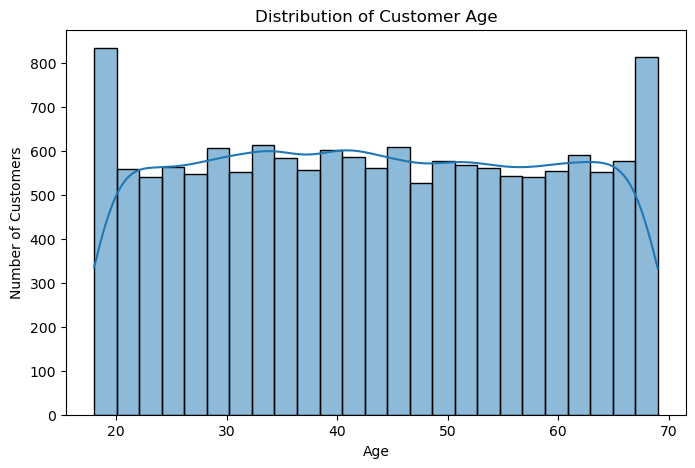

In [58]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df_work, x='Age', kde=True)
plt.title("Distribution of Customer Age")
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.show()
#Histogram of age

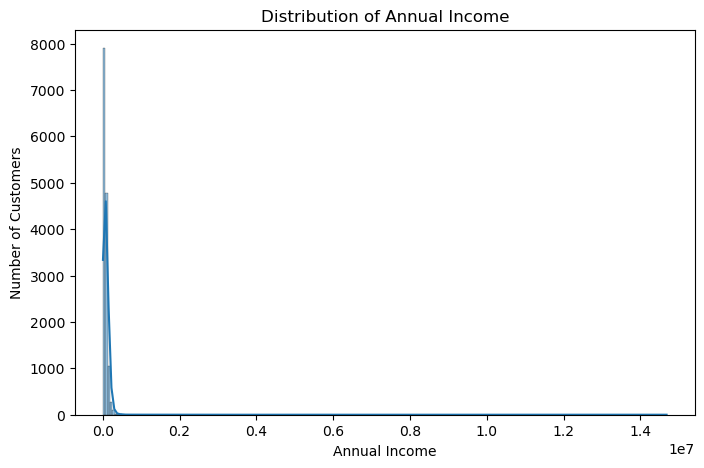

In [59]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df_work, x='Annual_Income', kde=True)
plt.title("Distribution of Annual Income")
plt.xlabel('Annual Income')
plt.ylabel('Number of Customers')
plt.show()
#Histogram of Annual Income

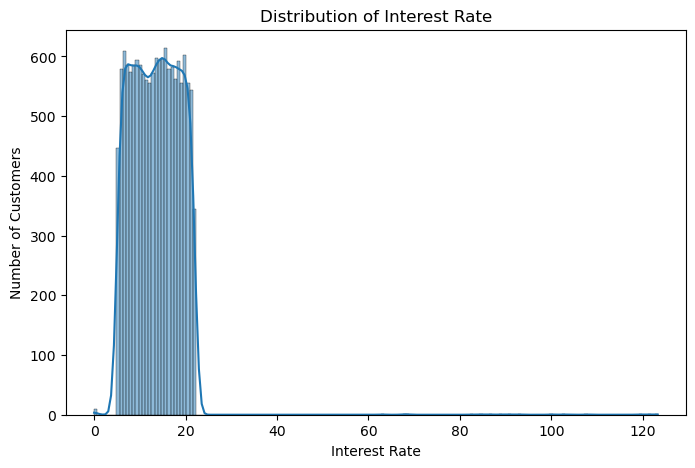

In [60]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df_work, x='Interest_Rate', kde=True)
plt.title("Distribution of Interest Rate")
plt.xlabel('Interest Rate')
plt.ylabel('Number of Customers')
plt.show()
#Histogram of Interest Rate

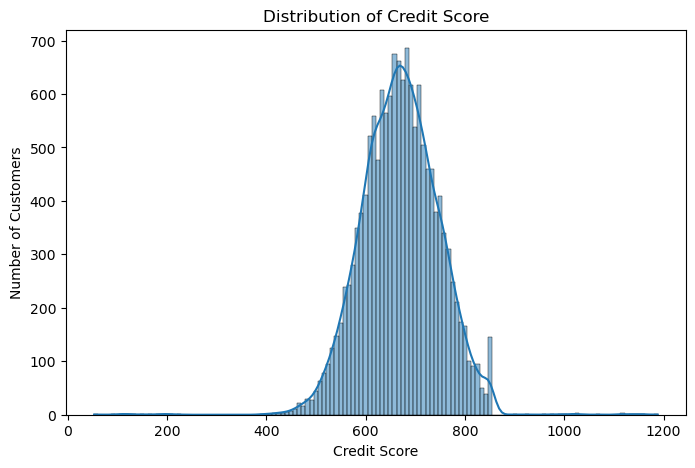

In [61]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df_work, x='Credit_Score', kde=True)
plt.title("Distribution of Credit Score")
plt.xlabel('Credit Score')
plt.ylabel('Number of Customers')
plt.show()
#Histogram of Credit Score

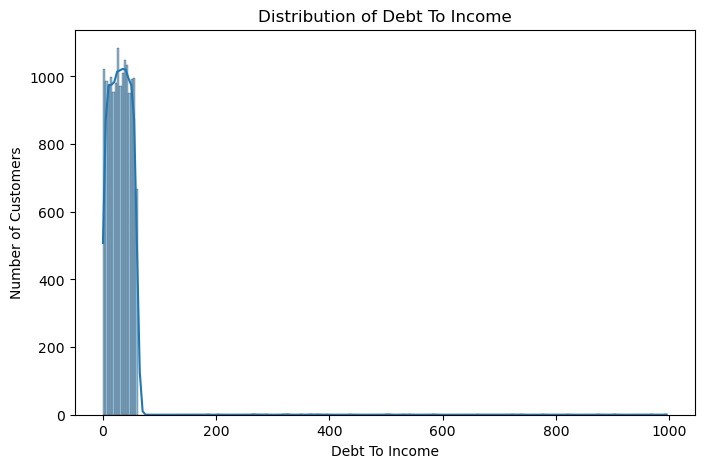

In [62]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df_work, x='Debt_To_Income', kde=True)
plt.title("Distribution of Debt To Income")
plt.xlabel('Debt To Income')
plt.ylabel('Number of Customers')
plt.show()
#Histogram of Debt To Income

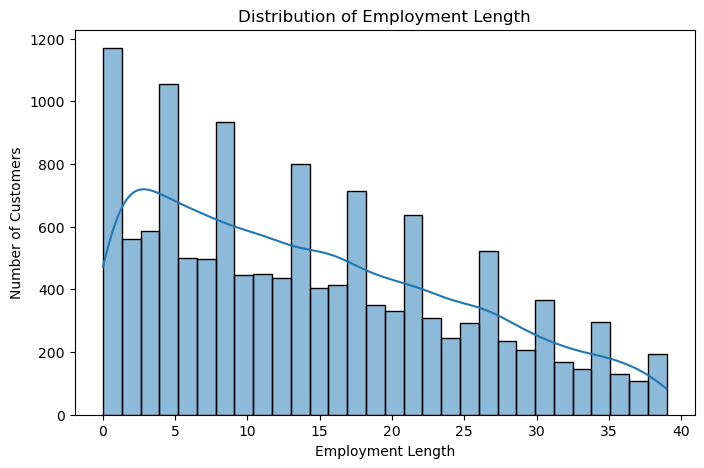

In [63]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df_work, x='Employment_Length', kde=True)
plt.title("Distribution of Employment Length")
plt.xlabel('Employment Length')
plt.ylabel('Number of Customers')
plt.show()
#Histogram of Employment Length

### Numerical columns - Boxplot 

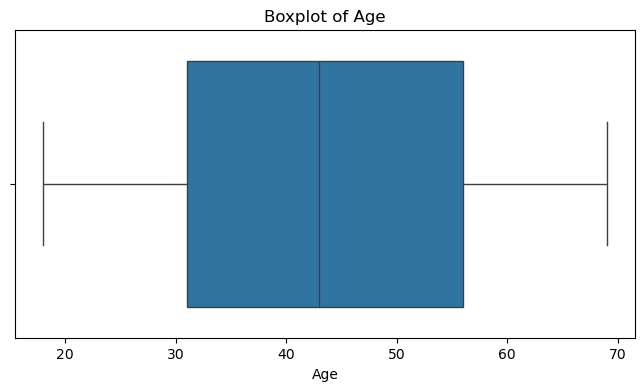

In [64]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df_work['Age'])
plt.title('Boxplot of Age')
plt.xlabel('Age')
plt.show()
#Histogram of Age     

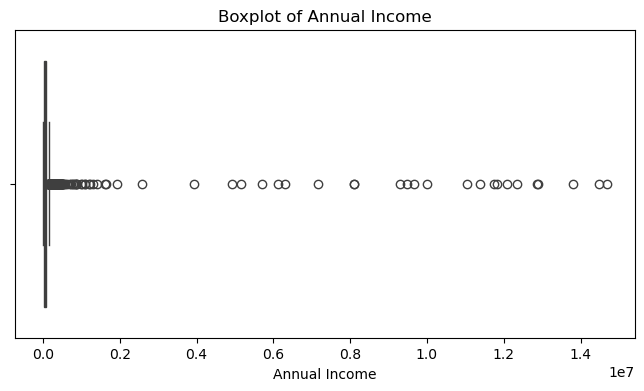

In [65]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df_work['Annual_Income'])
plt.title('Boxplot of Annual Income')
plt.xlabel('Annual Income')
plt.show()
#Histogram of Annual Income            

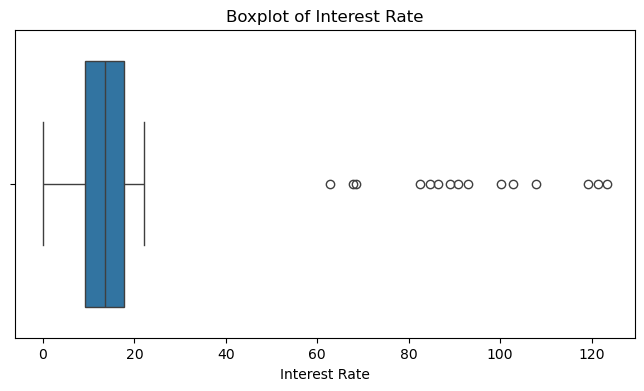

In [66]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df_work['Interest_Rate'])
plt.title('Boxplot of Interest Rate')
plt.xlabel('Interest Rate')
plt.show()
#Histogram of Interest Rate     

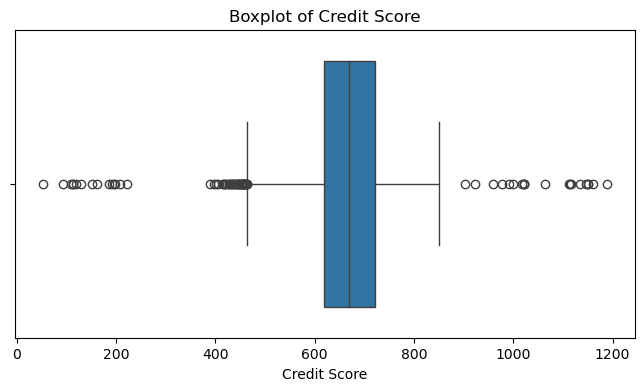

In [67]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df_work['Credit_Score'])
plt.title('Boxplot of Credit Score')
plt.xlabel('Credit Score')
plt.show()
#Histogram of Credit Score     

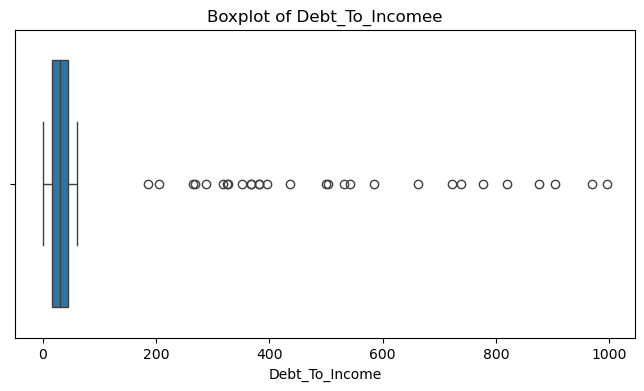

In [68]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df_work['Debt_To_Income'])
plt.title('Boxplot of Debt_To_Incomee')
plt.xlabel('Debt_To_Income')
plt.show()
#Histogram of Debt_To_Income

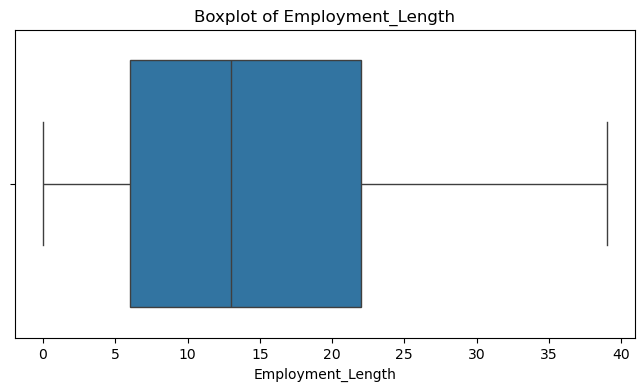

In [69]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df_work['Employment_Length'])
plt.title('Boxplot of Employment_Length')
plt.xlabel('Employment_Length')
plt.show()

### STEP 11 - Bivariate Analysis 

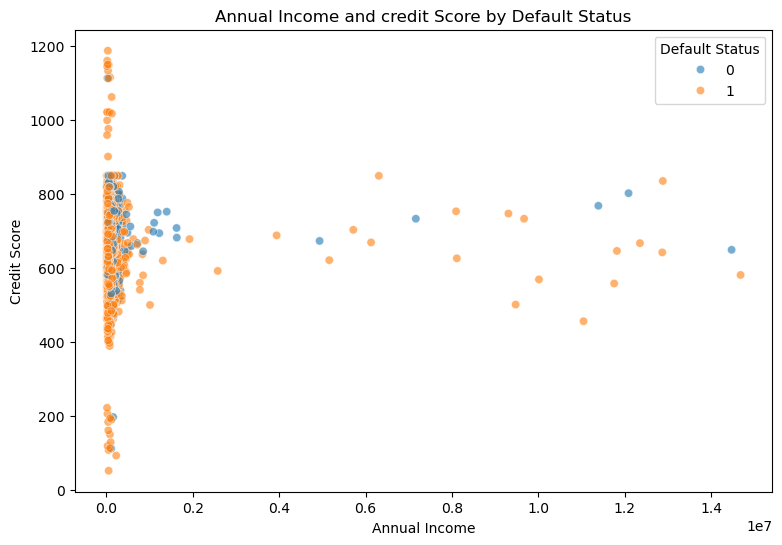

In [70]:
plt.figure(figsize=(9,6))
sns.scatterplot(
    data=df_work,
    x='Annual_Income',
    y='Credit_Score',
    hue='Default_Status',
    alpha=0.6
)
plt.title('Annual Income and credit Score by Default Status')
plt.xlabel('Annual Income')
plt.ylabel('Credit Score')
plt.legend(title='Default Status')
plt.show()

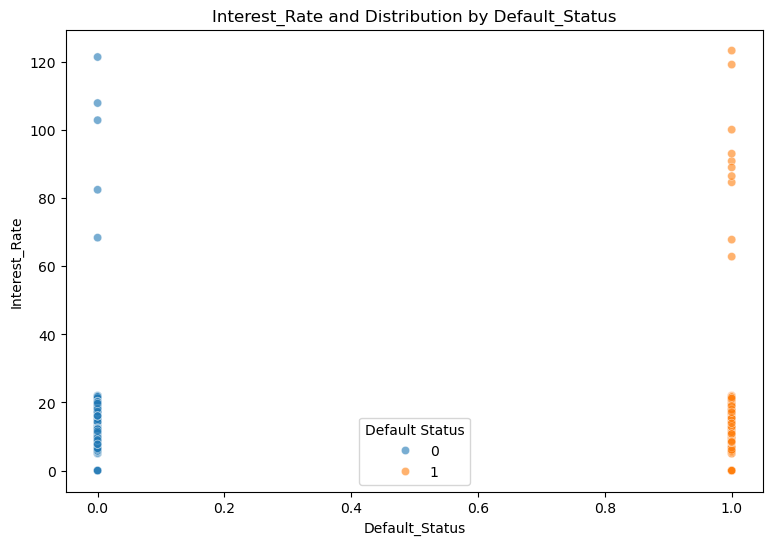

In [71]:
plt.figure(figsize=(9,6))
sns.scatterplot(
    data=df_work,
    x='Default_Status',
    y='Interest_Rate',
    hue='Default_Status',
    alpha=0.6
)
plt.title('Interest_Rate and Distribution by Default_Status')
plt.xlabel('Default_Status')
plt.ylabel('Interest_Rate')
plt.legend(title='Default Status')
plt.show()

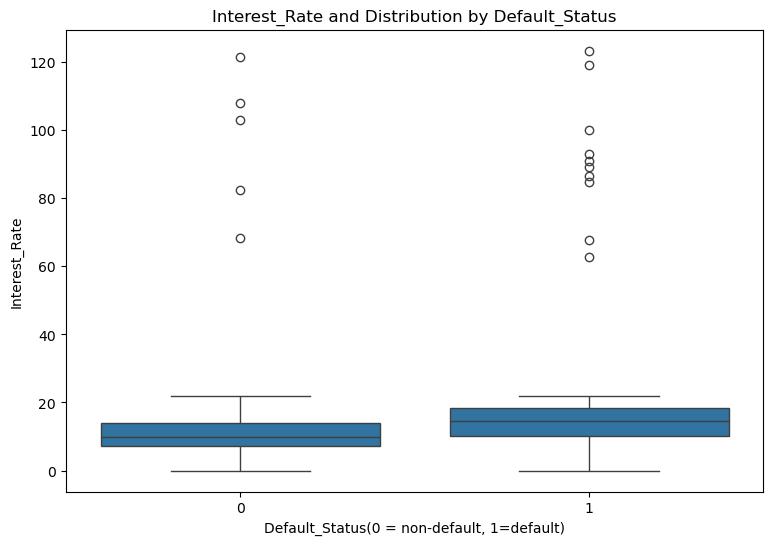

In [72]:
plt.figure(figsize=(9,6))
sns.boxplot(
    data=df_work,
    x='Default_Status',
    y='Interest_Rate'
)
plt.title('Interest_Rate and Distribution by Default_Status')
plt.xlabel('Default_Status(0 = non-default, 1=default)')
plt.ylabel('Interest_Rate')
plt.show()

In [73]:
# Count customers in each education and default-status group
education_default_counts = pd.crosstab(
    df_work["Education_Level"],
    df_work["Default_Status"]
)

print("Customer counts:")
display(education_default_counts)

# Calculate the percentage distribution within each education group
education_default_percentages = pd.crosstab(
    df_work["Education_Level"],
    df_work["Default_Status"],
    normalize="index"
) * 100

print("Default-status percentages within each education group:")
display(education_default_percentages.round(2))

Customer counts:


Default_Status,0,1
Education_Level,,
Associates,1,8
Bachelors,7,25
Doctorate,3,4
High School,9,25
Masters,4,14
ASSOCIATES,2,10
Associates,511,1667
BACHELORS,11,31
Bachelors,1333,4415


Default-status percentages within each education group:


Default_Status,0,1
Education_Level,,
Associates,11.11,88.89
Bachelors,21.88,78.12
Doctorate,42.86,57.14
High School,26.47,73.53
Masters,22.22,77.78
ASSOCIATES,16.67,83.33
Associates,23.46,76.54
BACHELORS,26.19,73.81
Bachelors,23.19,76.81


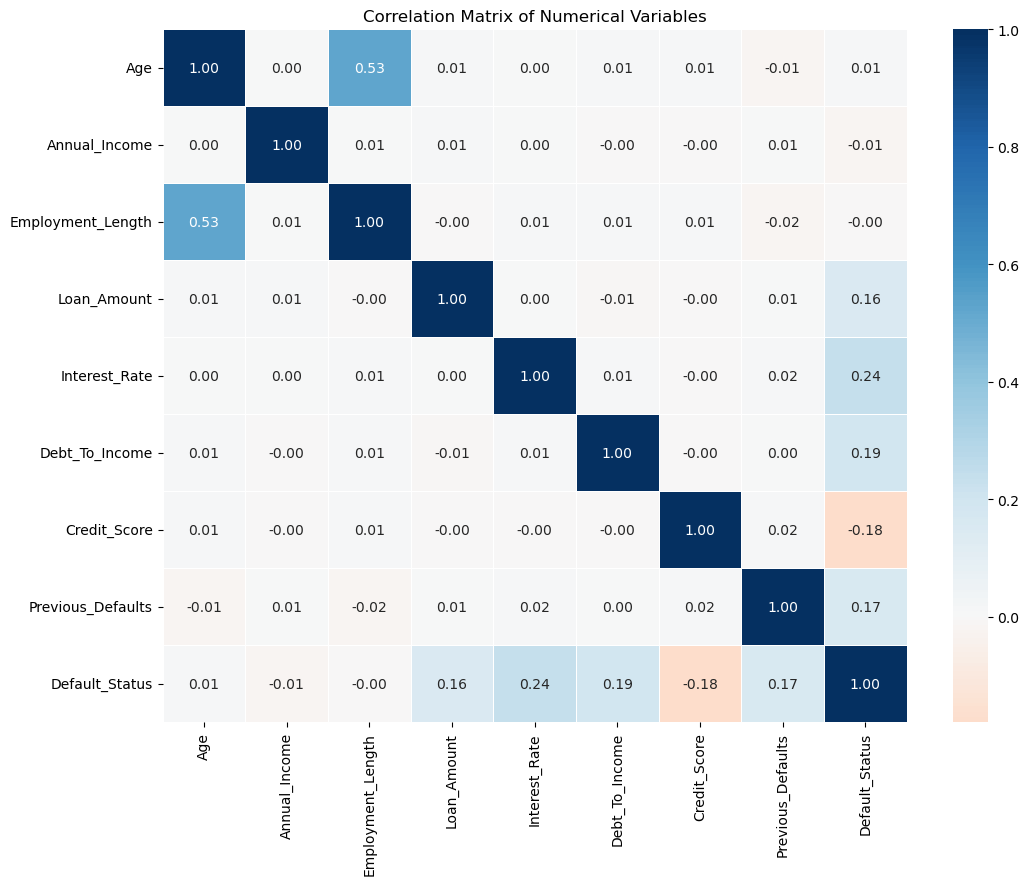

In [74]:
numeric_df = df_work.select_dtypes(include="number")
#Select numeric columns

correlation_matrix = numeric_df.corr()
#calculate correlation

plt.figure(figsize=(12,9))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='RdBu',
    center=0,
    linewidths=0.5
)

plt.title('Correlation Matrix of Numerical Variables')
plt.show()

## Conclusion

In this project, I performed Exploratory Data Analysis (EDA) on the lending default risk dataset to understand the data, check its quality, and explore patterns related to loan defaults.

First, I checked the dataset's structure, data types, descriptive statistics, missing values, and duplicate records. During data-quality checks, I identified issues such as duplicate records, missing values, and unusual values in columns like Age, Annual Income, Interest Rate, Debt-to-Income Ratio, and Credit Score.

I removed exact duplicate rows to make the dataset cleaner. I also used a separate working copy to investigate invalid age values. Missing values and extreme values were examined to understand their patterns. However, I did not assume that every extreme value was an error, as some values may be valid depending on the variable.

Next, I performed univariate analysis using histograms and boxplots to understand the distribution of numerical variables and identify potential outliers. I also performed bivariate analysis using scatterplots, interest-rate comparisons across default-status groups, and a cross-tabulation of education level against default status to explore relationships between variables and loan defaults.

Overall, this analysis helped me understand the dataset, identify data-quality issues, and explore patterns that may be related to loan defaults. Before moving to predictive modelling, the remaining missing values, unusual observations, and data-cleaning decisions need to be reviewed carefully.

This project helped me understand the importance of checking data quality, analysing variables step by step, and making conclusions based on actual results. The findings from this EDA can be used as a foundation for further analysis to investigate which customer and loan characteristics are associated with default status.
